In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn pymongo dnspython


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pymongo import MongoClient, ASCENDING, DESCENDING
from pymongo.errors import DuplicateKeyError

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    mean_absolute_error,
    r2_score
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
df = pd.read_csv("C:\env\RTA Dataset.csv")

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

df.head()

Dataset loaded successfully!
Number of rows: 12316
Number of columns: 32


,Time,Day_of_week,Age_band_of_driver,Sex_of_driver,Educational_level,Vehicle_driver_relation,Driving_experience,Type_of_vehicle,Owner_of_vehicle,Service_year_of_vehicle,...,Vehicle_movement,Casualty_class,Sex_of_casualty,Age_band_of_casualty,Casualty_severity,Work_of_casuality,Fitness_of_casuality,Pedestrian_movement,Cause_of_accident,Accident_severity
0,17:02:00,Monday,18-30,Male,Above high school,Employee,1-2yr,Automobile,Owner,Above 10yr,...,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Moving Backward,Slight Injury
1,17:02:00,Monday,31-50,Male,Junior high school,Employee,Above 10yr,Public (> 45 seats),Owner,5-10yrs,...,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Overtaking,Slight Injury
2,17:02:00,Monday,18-30,Male,Junior high school,Employee,1-2yr,Lorry (41?100Q),Owner,NaN,...,Going straight,Driver or rider,Male,31-50,3,Driver,NaN,Not a Pedestrian,Changing lane to the left,Serious Injury
3,1:06:00,Sunday,18-30,Male,Junior high school,Employee,5-10yr,Public (> 45 seats),Governmental,NaN,...,Going straight,Pedestrian,Female,18-30,3,Driver,Normal,Not a Pedestrian,Changing lane to the right,Slight Injury
4,1:06:00,Sunday,18-30,Male,Junior high school,Employee,2-5yr,NaN,Owner,5-10yrs,...,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Overtaking,Slight Injury


In [5]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum().sort_values(ascending=False).head(15))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nAccident severity categories:")
print(df["Accident_severity"].value_counts())

Column names:
['Time', 'Day_of_week', 'Age_band_of_driver', 'Sex_of_driver', 'Educational_level', 'Vehicle_driver_relation', 'Driving_experience', 'Type_of_vehicle', 'Owner_of_vehicle', 'Service_year_of_vehicle', 'Defect_of_vehicle', 'Area_accident_occured', 'Lanes_or_Medians', 'Road_allignment', 'Types_of_Junction', 'Road_surface_type', 'Road_surface_conditions', 'Light_conditions', 'Weather_conditions', 'Type_of_collision', 'Number_of_vehicles_involved', 'Number_of_casualties', 'Vehicle_movement', 'Casualty_class', 'Sex_of_casualty', 'Age_band_of_casualty', 'Casualty_severity', 'Work_of_casuality', 'Fitness_of_casuality', 'Pedestrian_movement', 'Cause_of_accident', 'Accident_severity']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12316 entries, 0 to 12315
Data columns (total 32 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   Time                         12316 non-null  object
 

In [6]:
df.columns = df.columns.str.strip()

df = df.drop_duplicates().reset_index(drop=True)

print("Rows after removing duplicates:", len(df))
print("Columns:", len(df.columns))

Rows after removing duplicates: 12316
Columns: 32


In [7]:
print(df["Accident_severity"].value_counts(dropna=False))
print()
print(df["Number_of_casualties"].describe())

Accident_severity
Slight Injury     10415
Serious Injury     1743
Fatal injury        158
Name: count, dtype: int64

count    12316.000000
mean         1.548149
std          1.007179
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max          8.000000
Name: Number_of_casualties, dtype: float64


In [8]:
df["Number_of_casualties"] = pd.to_numeric(
    df["Number_of_casualties"], errors="coerce"
)

df = df.dropna(
    subset=["Accident_severity", "Number_of_casualties"]
).copy()

df = df.reset_index(drop=True)

# Remove accidental leading/trailing spaces from text values
for col in df.select_dtypes(include=["object"]).columns:
    df[col] = df[col].str.strip()
    df[col] = df[col].replace("", np.nan)

print("Clean dataset shape:", df.shape)
print("Missing target values:",
      df[["Accident_severity", "Number_of_casualties"]].isna().sum())

Clean dataset shape: (12316, 32)
Missing target values: Accident_severity       0
Number_of_casualties    0
dtype: int64


In [9]:
MONGO_URI = "mongodb://localhost:27017/"

In [10]:
client = MongoClient(MONGO_URI, serverSelectionTimeoutMS=5000)

# Test the connection
client.admin.command("ping")

db = client["RoadAccidentDB"]
accidents = db["accidents"]

print("Connected to MongoDB successfully!")
print("Database:", db.name)
print("Collection:", accidents.name)

Connected to MongoDB successfully!
Database: RoadAccidentDB
Collection: accidents


In [11]:
# Make the upload repeatable without duplicating existing data.
accidents.delete_many({})

records = df.to_dict(orient="records")

# Replace pandas NaN values with Python None
for record in records:
    for key, value in record.items():
        if pd.isna(value):
            record[key] = None
        elif isinstance(value, np.integer):
            record[key] = int(value)
        elif isinstance(value, np.floating):
            record[key] = float(value)

if records:
    result = accidents.insert_many(records)

    print("Documents inserted:", len(result.inserted_ids))
else:
    print("No records to insert.")

Documents inserted: 12316


In [12]:
print("Total MongoDB documents:", accidents.count_documents({}))

sample = accidents.find_one()
print("\nSample MongoDB document:")
print(sample)

Total MongoDB documents: 12316

Sample MongoDB document:
{'_id': ObjectId('6ae37654753ded0bf12991fe'), 'Time': '17:02:00', 'Day_of_week': 'Monday', 'Age_band_of_driver': '18-30', 'Sex_of_driver': 'Male', 'Educational_level': 'Above high school', 'Vehicle_driver_relation': 'Employee', 'Driving_experience': '1-2yr', 'Type_of_vehicle': 'Automobile', 'Owner_of_vehicle': 'Owner', 'Service_year_of_vehicle': 'Above 10yr', 'Defect_of_vehicle': 'No defect', 'Area_accident_occured': 'Residential areas', 'Lanes_or_Medians': None, 'Road_allignment': 'Tangent road with flat terrain', 'Types_of_Junction': 'No junction', 'Road_surface_type': 'Asphalt roads', 'Road_surface_conditions': 'Dry', 'Light_conditions': 'Daylight', 'Weather_conditions': 'Normal', 'Type_of_collision': 'Collision with roadside-parked vehicles', 'Number_of_vehicles_involved': 2, 'Number_of_casualties': 2, 'Vehicle_movement': 'Going straight', 'Casualty_class': 'na', 'Sex_of_casualty': 'na', 'Age_band_of_casualty': 'na', 'Casualt

In [13]:
demo = db["crud_demo"]

demo.delete_many({})

result = demo.insert_one({
    "record_type": "demo",
    "weather": "Rainy",
    "vehicles": 2,
    "severity": "Slight Injury"
})

print("Inserted ID:", result.inserted_id)

Inserted ID: 6ae37673753ded0bf129c21a


In [14]:
for doc in demo.find():
    print(doc)

{'_id': ObjectId('6ae37673753ded0bf129c21a'), 'record_type': 'demo', 'weather': 'Rainy', 'vehicles': 2, 'severity': 'Slight Injury'}


In [15]:
result = demo.update_one(
    {"record_type": "demo"},
    {"$set": {"weather": "Sunny"}}
)

print("Documents updated:", result.modified_count)
print(demo.find_one({"record_type": "demo"}))

Documents updated: 1
{'_id': ObjectId('6ae37673753ded0bf129c21a'), 'record_type': 'demo', 'weather': 'Sunny', 'vehicles': 2, 'severity': 'Slight Injury'}


In [16]:
result = demo.delete_one({"record_type": "demo"})

print("Documents deleted:", result.deleted_count)

Documents deleted: 1


In [17]:
accidents.create_index([("Accident_severity", ASCENDING)])
accidents.create_index([("Day_of_week", ASCENDING)])
accidents.create_index([
    ("Accident_severity", ASCENDING),
    ("Day_of_week", ASCENDING)
])

print("Indexes created:")
print(accidents.index_information())

Indexes created:
{'_id_': {'v': 2, 'key': [('_id', 1)]}, 'Accident_severity_1': {'v': 2, 'key': [('Accident_severity', 1)]}, 'Day_of_week_1': {'v': 2, 'key': [('Day_of_week', 1)]}, 'Accident_severity_1_Day_of_week_1': {'v': 2, 'key': [('Accident_severity', 1), ('Day_of_week', 1)]}}


In [18]:
query = {"Accident_severity": "Slight Injury"}

print("Matching records:", accidents.count_documents(query))

for doc in accidents.find(query).limit(5):
    print(doc["Day_of_week"], doc["Accident_severity"])

Matching records: 10415
Monday Slight Injury
Monday Slight Injury
Sunday Slight Injury
Sunday Slight Injury
Friday Slight Injury


In [19]:
explanation = accidents.find(
    {"Accident_severity": "Slight Injury"}
).explain()

print("Execution statistics:")
print(explanation["executionStats"])

Execution statistics:
{'executionSuccess': True, 'nReturned': 10415, 'executionTimeMillis': 19, 'totalKeysExamined': 10415, 'totalDocsExamined': 10415, 'executionStages': {'isCached': False, 'stage': 'FETCH', 'nReturned': 10415, 'executionTimeMillisEstimate': 12, 'works': 10416, 'advanced': 10415, 'needTime': 0, 'needYield': 0, 'saveState': 2, 'restoreState': 2, 'isEOF': 1, 'nss': 'RoadAccidentDB.accidents', 'docsExamined': 10415, 'alreadyHasObj': 0, 'inputStage': {'stage': 'IXSCAN', 'nReturned': 10415, 'executionTimeMillisEstimate': 12, 'works': 10416, 'advanced': 10415, 'needTime': 0, 'needYield': 0, 'saveState': 2, 'restoreState': 2, 'isEOF': 1, 'nss': 'RoadAccidentDB.accidents', 'keyPattern': {'Accident_severity': 1}, 'indexName': 'Accident_severity_1', 'isMultiKey': False, 'multiKeyPaths': {'Accident_severity': []}, 'isUnique': False, 'isSparse': False, 'isPartial': False, 'indexVersion': 2, 'direction': 'forward', 'indexBounds': {'Accident_severity': ['["Slight Injury", "Slight I

In [20]:
pipeline = [
    {
        "$group": {
            "_id": "$Accident_severity",
            "total_accidents": {"$sum": 1}
        }
    },
    {"$sort": {"total_accidents": -1}}
]

for item in accidents.aggregate(pipeline):
    print(item)

{'_id': 'Slight Injury', 'total_accidents': 10415}
{'_id': 'Serious Injury', 'total_accidents': 1743}
{'_id': 'Fatal injury', 'total_accidents': 158}


In [21]:
pipeline = [
    {
        "$group": {
            "_id": "$Day_of_week",
            "total_accidents": {"$sum": 1},
            "average_casualties": {
                "$avg": "$Number_of_casualties"
            }
        }
    },
    {"$sort": {"total_accidents": -1}}
]

weekday_summary = list(accidents.aggregate(pipeline))

for item in weekday_summary:
    print(item)

{'_id': 'Friday', 'total_accidents': 2041, 'average_casualties': 1.540421362077413}
{'_id': 'Thursday', 'total_accidents': 1851, 'average_casualties': 1.4700162074554295}
{'_id': 'Wednesday', 'total_accidents': 1840, 'average_casualties': 1.4081521739130434}
{'_id': 'Tuesday', 'total_accidents': 1770, 'average_casualties': 1.4621468926553671}
{'_id': 'Monday', 'total_accidents': 1681, 'average_casualties': 1.529446757882213}
{'_id': 'Saturday', 'total_accidents': 1666, 'average_casualties': 1.6482593037214885}
{'_id': 'Sunday', 'total_accidents': 1467, 'average_casualties': 1.8445807770961145}


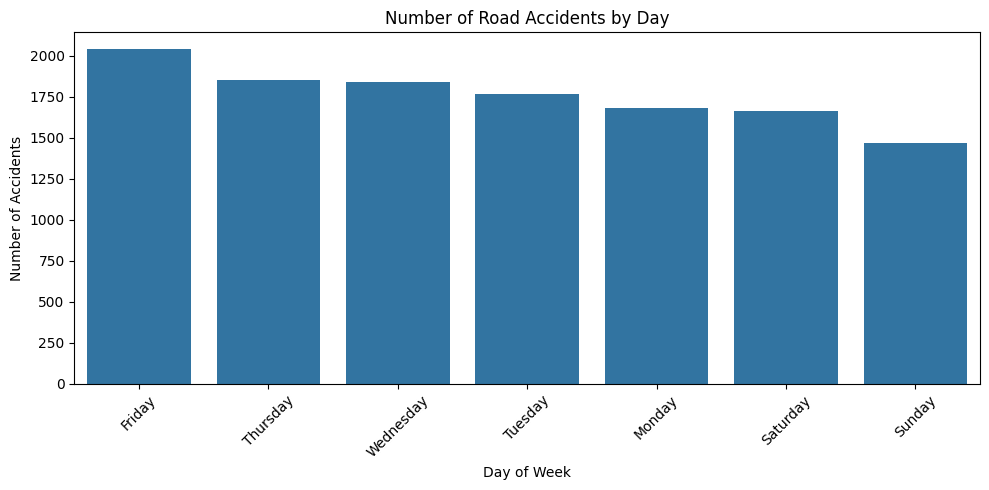

In [22]:
summary_df = pd.DataFrame(weekday_summary)

summary_df = summary_df.rename(
    columns={"_id": "Day_of_week"}
)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=summary_df,
    x="Day_of_week",
    y="total_accidents"
)

plt.title("Number of Road Accidents by Day")
plt.xlabel("Day of Week")
plt.ylabel("Number of Accidents")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [23]:
mongo_records = list(accidents.find({}, {"_id": 0}))
ml_df = pd.DataFrame(mongo_records)

print("Records retrieved from MongoDB:", len(ml_df))
ml_df.head()

Records retrieved from MongoDB: 12316


,Time,Day_of_week,Age_band_of_driver,Sex_of_driver,Educational_level,Vehicle_driver_relation,Driving_experience,Type_of_vehicle,Owner_of_vehicle,Service_year_of_vehicle,...,Vehicle_movement,Casualty_class,Sex_of_casualty,Age_band_of_casualty,Casualty_severity,Work_of_casuality,Fitness_of_casuality,Pedestrian_movement,Cause_of_accident,Accident_severity
0,17:02:00,Monday,18-30,Male,Above high school,Employee,1-2yr,Automobile,Owner,Above 10yr,...,Going straight,na,na,na,na,None,None,Not a Pedestrian,Moving Backward,Slight Injury
1,17:02:00,Monday,31-50,Male,Junior high school,Employee,Above 10yr,Public (> 45 seats),Owner,5-10yrs,...,Going straight,na,na,na,na,None,None,Not a Pedestrian,Overtaking,Slight Injury
2,17:02:00,Monday,18-30,Male,Junior high school,Employee,1-2yr,Lorry (41?100Q),Owner,None,...,Going straight,Driver or rider,Male,31-50,3,Driver,None,Not a Pedestrian,Changing lane to the left,Serious Injury
3,1:06:00,Sunday,18-30,Male,Junior high school,Employee,5-10yr,Public (> 45 seats),Governmental,None,...,Going straight,Pedestrian,Female,18-30,3,Driver,Normal,Not a Pedestrian,Changing lane to the right,Slight Injury
4,1:06:00,Sunday,18-30,Male,Junior high school,Employee,2-5yr,None,Owner,5-10yrs,...,Going straight,na,na,na,na,None,None,Not a Pedestrian,Overtaking,Slight Injury


In [24]:
# Classification: predict accident severity
X_class = ml_df.drop(
    columns=["Accident_severity", "Number_of_casualties"]
)
y_class = ml_df["Accident_severity"]

# Regression: predict number of casualties
X_reg = ml_df.drop(
    columns=["Number_of_casualties", "Accident_severity"]
)
y_reg = ml_df["Number_of_casualties"].astype(float)

print("Classification features:", X_class.shape)
print("Classification target:", y_class.shape)
print("Regression features:", X_reg.shape)
print("Regression target:", y_reg.shape)

Classification features: (12316, 30)
Classification target: (12316,)
Regression features: (12316, 30)
Regression target: (12316,)


In [25]:
def build_preprocessor(X):
    numeric_features = X.select_dtypes(
        include=["number"]
    ).columns.tolist()

    categorical_features = X.select_dtypes(
        include=["object", "category", "bool"]
    ).columns.tolist()

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor = ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ])

    return preprocessor

print("Preprocessing pipeline defined.")

Preprocessing pipeline defined.


In [26]:
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_class,
    y_class,
    test_size=0.20,
    random_state=42,
    stratify=y_class
)

print("Training records:", len(X_train_c))
print("Testing records:", len(X_test_c))

Training records: 9852
Testing records: 2464


In [27]:
classifier = Pipeline([
    ("preprocessing", build_preprocessor(X_train_c)),
    ("model", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

classifier.fit(X_train_c, y_train_c)

print("Random Forest classifier trained successfully!")

Random Forest classifier trained successfully!


In [28]:
y_pred_c = classifier.predict(X_test_c)

print("Actual values:")
print(y_test_c.head(10).tolist())

print("\nPredicted values:")
print(y_pred_c[:10].tolist())

Actual values:
['Slight Injury', 'Slight Injury', 'Slight Injury', 'Serious Injury', 'Slight Injury', 'Slight Injury', 'Slight Injury', 'Serious Injury', 'Slight Injury', 'Slight Injury']

Predicted values:
['Slight Injury', 'Slight Injury', 'Slight Injury', 'Slight Injury', 'Slight Injury', 'Slight Injury', 'Slight Injury', 'Slight Injury', 'Slight Injury', 'Slight Injury']


In [29]:
accuracy = accuracy_score(y_test_c, y_pred_c)

precision = precision_score(
    y_test_c, y_pred_c,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    y_test_c, y_pred_c,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    y_test_c, y_pred_c,
    average="weighted",
    zero_division=0
)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

print("\nDetailed Classification Report:")
print(classification_report(
    y_test_c,
    y_pred_c,
    zero_division=0
))

Accuracy:  0.8458
Precision: 0.7153
Recall:    0.8458
F1-score:  0.7751

Detailed Classification Report:
                precision    recall  f1-score   support

  Fatal injury       0.00      0.00      0.00        31
Serious Injury       0.00      0.00      0.00       349
 Slight Injury       0.85      1.00      0.92      2084

      accuracy                           0.85      2464
     macro avg       0.28      0.33      0.31      2464
  weighted avg       0.72      0.85      0.78      2464



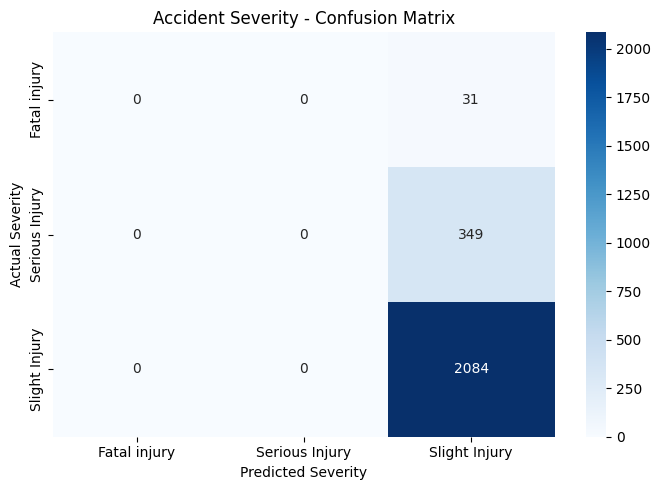

In [30]:
labels = classifier.named_steps["model"].classes_

cm = confusion_matrix(
    y_test_c, y_pred_c,
    labels=labels
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Accident Severity - Confusion Matrix")
plt.xlabel("Predicted Severity")
plt.ylabel("Actual Severity")
plt.tight_layout()
plt.show()

In [31]:
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg,
    y_reg,
    test_size=0.20,
    random_state=42
)

print("Regression training records:", len(X_train_r))
print("Regression testing records:", len(X_test_r))

Regression training records: 9852
Regression testing records: 2464


In [32]:
regressor = Pipeline([
    ("preprocessing", build_preprocessor(X_train_r)),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

regressor.fit(X_train_r, y_train_r)

print("Random Forest regressor trained successfully!")

Random Forest regressor trained successfully!


In [33]:
y_pred_r = regressor.predict(X_test_r)

mae = mean_absolute_error(y_test_r, y_pred_r)
r2 = r2_score(y_test_r, y_pred_r)

print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"R² Score: {r2:.4f}")

Mean Absolute Error (MAE): 0.4020
R² Score: 0.6588


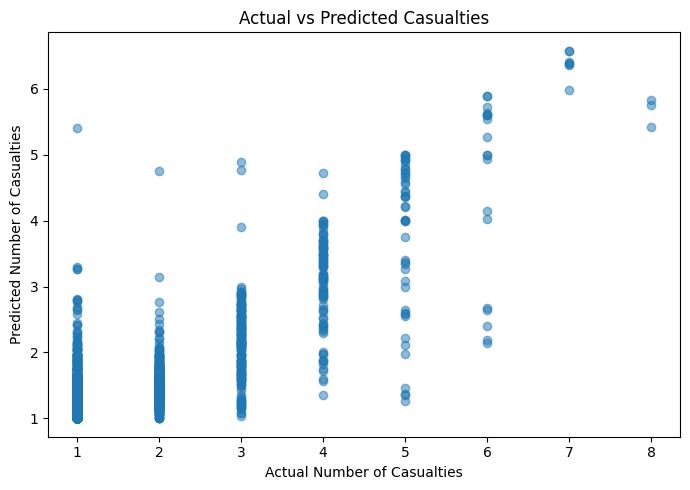

In [34]:
plt.figure(figsize=(7, 5))

plt.scatter(
    y_test_r,
    y_pred_r,
    alpha=0.5
)

plt.xlabel("Actual Number of Casualties")
plt.ylabel("Predicted Number of Casualties")
plt.title("Actual vs Predicted Casualties")

plt.tight_layout()
plt.show()

In [35]:
model_results = db["model_results"]

model_results.insert_many([
    {
        "model_name": "Random Forest Classifier",
        "task": "Accident Severity Classification",
        "accuracy": float(accuracy),
        "precision_weighted": float(precision),
        "recall_weighted": float(recall),
        "f1_weighted": float(f1)
    },
    {
        "model_name": "Random Forest Regressor",
        "task": "Casualty Count Prediction",
        "mae": float(mae),
        "r2_score": float(r2)
    }
])

print("Model evaluation results saved to MongoDB!")

Model evaluation results saved to MongoDB!


In [36]:
for result in model_results.find({}, {"_id": 0}):
    print(result)

{'model_name': 'Random Forest Classifier', 'task': 'Accident Severity Classification', 'accuracy': 0.8457792207792207, 'precision_weighted': 0.7153424903019059, 'recall_weighted': 0.8457792207792207, 'f1_weighted': 0.7751116517607284}
{'model_name': 'Random Forest Regressor', 'task': 'Casualty Count Prediction', 'mae': 0.40202110389610385, 'r2_score': 0.6587617775190597}


In [37]:
# Take one existing record as an example input.
# This is a demonstration, not an independent new accident.
new_accident = X_class.iloc[[0]].copy()

predicted_severity = classifier.predict(new_accident)[0]

new_accident_reg = X_reg.iloc[[0]].copy()
predicted_casualties = regressor.predict(new_accident_reg)[0]

print("Predicted accident severity:", predicted_severity)
print("Predicted casualty count:", round(float(predicted_casualties), 2))

Predicted accident severity: Slight Injury
Predicted casualty count: 1.56


In [38]:
db.create_collection(
    "validated_accidents",
    validator={
        "$jsonSchema": {
            "bsonType": "object",
            "required": [
                "Number_of_vehicles_involved",
                "Number_of_casualties"
            ],
            "properties": {
                "Number_of_vehicles_involved": {
                    "bsonType": ["int", "long", "double"],
                    "minimum": 0
                },
                "Number_of_casualties": {
                    "bsonType": ["int", "long", "double"],
                    "minimum": 0
                }
            }
        }
    }
)

print("Validation-enabled collection created.")

Validation-enabled collection created.


In [39]:
validated = db["validated_accidents"]

validated.insert_one({
    "Number_of_vehicles_involved": 2,
    "Number_of_casualties": 1
})

print("Valid document inserted successfully.")

Valid document inserted successfully.


In [40]:
import pandas as pd
import numpy as np
import joblib
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, mean_absolute_error, r2_score
)

FEATURES = [
    "Day_of_week",
    "Weather_conditions",
    "Road_surface_conditions",
    "Light_conditions",
    "Types_of_Junction",
    "Type_of_vehicle",
    "Driving_experience",
    "Number_of_vehicles_involved"
]

print("Model features defined.")

Model features defined.


In [41]:
required_columns = FEATURES + [
    "Accident_severity",
    "Number_of_casualties"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    print("Missing columns:", missing_columns)
else:
    print("All required columns are available!")

All required columns are available!


In [42]:
project_df = df[required_columns].copy()

project_df["Number_of_casualties"] = pd.to_numeric(
    project_df["Number_of_casualties"],
    errors="coerce"
)

project_df = project_df.dropna(
    subset=["Accident_severity", "Number_of_casualties"]
)

X = project_df[FEATURES]
y_severity = project_df["Accident_severity"].astype(str)
y_casualties = project_df["Number_of_casualties"].astype(float)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_severity,
    test_size=0.20,
    random_state=42,
    stratify=y_severity
)

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X,
    y_casualties,
    test_size=0.20,
    random_state=42
)

print("Training data prepared.")

Training data prepared.


In [43]:
numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = [
    col for col in FEATURES
    if col not in numeric_features
]

def make_preprocessor():
    return ColumnTransformer([
        (
            "numeric",
            SimpleImputer(strategy="median"),
            numeric_features
        ),
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_features
        )
    ])

In [44]:
classifier = Pipeline([
    ("preprocessing", make_preprocessor()),
    ("model", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

regressor = Pipeline([
    ("preprocessing", make_preprocessor()),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

classifier.fit(X_train, y_train)
regressor.fit(X_train_r, y_train_r)

# Save both complete pipelines, including preprocessing
joblib.dump(classifier, "severity_model.joblib")
joblib.dump(regressor, "casualty_model.joblib")

print("Both models saved successfully!")

Both models saved successfully!


In [45]:
pred_c = classifier.predict(X_test)
pred_r = regressor.predict(X_test_r)

metrics = pd.DataFrame([
    {
        "Model": "Random Forest Classifier",
        "Accuracy": accuracy_score(y_test, pred_c),
        "Precision": precision_score(
            y_test, pred_c, average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred_c, average="weighted", zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, pred_c, average="weighted", zero_division=0
        ),
        "MAE": np.nan,
        "R2 Score": np.nan
    },
    {
        "Model": "Random Forest Regressor",
        "Accuracy": np.nan,
        "Precision": np.nan,
        "Recall": np.nan,
        "F1 Score": np.nan,
        "MAE": mean_absolute_error(y_test_r, pred_r),
        "R2 Score": r2_score(y_test_r, pred_r)
    }
])

metrics.to_csv("model_metrics.csv", index=False)
display(metrics)

print("Model metrics saved.")

,Model,Accuracy,Precision,Recall,F1 Score,MAE,R2 Score
0,Random Forest Classifier,0.747971,0.747702,0.747971,0.747706,NaN,NaN
1,Random Forest Regressor,NaN,NaN,NaN,NaN,0.635581,0.162544


Model metrics saved.
